# Run sorters and analyze them

Now that we've explored our data and have cleaned/preprocessed it, it's finally time to sort!

Let's read in our preprocessed recording

In [1]:
from pathlib import Path

import spikeinterface.full as si

si.set_global_job_kwargs(n_jobs=2)

In [2]:
# Modify this to where you downloaded your datasets

# Modify this to where you downloaded your datasets
home = Path.home()
base_data_folder = Path(home / "school_2026/data/")
results_folder = Path(home / "school_2026/results/")
preprocessed_path = results_folder / Path('preprocessed')
preprocessed_recording = si.load(preprocessed_path)

In [3]:
%matplotlib widget
si.plot_traces(preprocessed_recording, backend="ipywidgets")

AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

### Check installation

We can now run spike sorting on the above recording. We will use different spike sorters for this demonstration, to show how easy `SpikeInterface` makes it easy to interchengably run different sorters :)

Let's first check the available and installed sorters in `SpikeInterface`.
We will sort the bandpass cached filtered recording the `recording_saved` object.

In [4]:
si.available_sorters()

['combinato',
 'dartsort',
 'hdsort',
 'herdingspikes',
 'ironclust',
 'kilosort',
 'kilosort2',
 'kilosort2_5',
 'kilosort3',
 'kilosort4',
 'kilosort4like',
 'lupin',
 'mountainsort4',
 'mountainsort5',
 'pykilosort',
 'rtsort',
 'simple',
 'spykingcircus',
 'spykingcircus2',
 'tridesclous',
 'tridesclous2',
 'vanillasort',
 'waveclus',
 'yass']

In [5]:
si.installed_sorters()

['kilosort4',
 'kilosort4like',
 'lupin',
 'simple',
 'spykingcircus2',
 'tridesclous2']

The `spikeinterface.sortingcomponents` module includes functions that can be used to create custom spike sorting pipelines built-in in `SpikeInterface`. We have used it to create some sorters

* `lupin` (developed by the SpikeInterface team - primarily Sam Garcia and Pierre Yger)
* `tridesclous2` (developed by Samuel Garcia)
* `spykingcircus2` (developed by Pierre Yger)
* `simple` which is only for demo and teaching

Let's run one now. Every sorter comes with a dizzying array of parameters, which we can check using `get_default_sorter_params`

In [6]:
si.get_default_sorter_params('lupin')

{'apply_preprocessing': True,
 'preprocessing_dict': None,
 'apply_motion_correction': False,
 'motion_correction_preset': 'dredge_fast',
 'clustering_ms_before': 0.3,
 'clustering_ms_after': 1.3,
 'whitening_radius_um': 100.0,
 'detection_radius_um': 50.0,
 'features_radius_um': 120.0,
 'split_radius_um': 60.0,
 'template_radius_um': 100.0,
 'merge_similarity_lag_ms': 0.5,
 'freq_min': 150.0,
 'freq_max': 7000.0,
 'cache_preprocessing_mode': 'auto',
 'peak_sign': 'neg',
 'detect_threshold': 5.0,
 'n_peaks_per_channel': 5000,
 'n_svd_components_per_channel': 5,
 'n_pca_features': 4,
 'clustering_recursive_depth': 3,
 'ms_before': 1.0,
 'ms_after': 2.5,
 'template_sparsify_threshold': 1.0,
 'template_min_snr_ptp': 4.0,
 'template_max_jitter_ms': 0.2,
 'template_matching_engine': 'wobble',
 'min_firing_rate': 0.1,
 'gather_mode': 'memory',
 'job_kwargs': {},
 'seed': None,
 'save_array': True,
 'debug': False}

### Run sorter installed locally

This run a sorter which is installed in the current python environements.

In [10]:
sorter_params = {'apply_motion_correction': False, 'apply_preprocessing': True}

In [12]:
sorting_lupin = si.run_sorter(
    sorter_name='lupin', 
    recording=preprocessed_recording,
    folder=results_folder / 'sorting_lupin',
    verbose=True,
    remove_existing_folder=True,
    **sorter_params
)


                            .::----::..
                 ..:-+#%*+#%@@@@@@@+..:+#+.
                .+@%%@@@@@@@@@@@@@@#:  .=@=
                -@@@@@@@@@@@@@@@@@@%-. .=@*
                .@@@@@@@@@@@@@@@@@@@*. .-%#
                 %@@@@@@@@@@@@@@@@@@*.  :#%
                 =%%@@@@@@@@@@@@@@%%+:  .+@.
                 -%#@@@@@@@@@@@@@@%*==  .-@.
                 :#%@@@@@@@@@@@@@@%#+#  .=@.
                 .+%@@@@@@@@@@@@@@@%#@. .+@.
                 .+*#@@@@@@@@@@@@@@@%@. .+@:
                 .=%+@@@@@@@@@@@@@@@@*.  =%-.
                  :#%##@@@@@@@@@@@@%%-.  :%+.
               ..:=**%@@@@@@@@@@@@@@@:.  .%%......
             .+#@%%%@**@%@@@@@@@@@@@*....=%@%@@@@@%=..
            .*@@@@@@@@@@@=#@@@@@@@@@@*=:.:.#@@@@@@%%-.
           .-%%@@@@@@@@@@@@@#+%@+-::-+=:=::+@@@@@@##-.
           .:%@@@@@@@@@@@@@@@@@%+%##*%%%**%@@@@@@##+.
            .+@@@@@@@@@@@@@@@@#***++***@@@@@@@@%%%=.
             .:*@@@@@@@@%=-.....   ....:-*%%%%%+-.
                 ..:-:..
                       

write_memory (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

noise_level (workers: 2 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

get protoype waveforms (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

detect peaks (matched_filtering) (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

detect_peaks(): 63237 peaks found
select_peaks(): 63237 peaks kept for clustering


... (6 outputs left out)

/run/media/pierre/Secondary/pierre/softwares/spikeinterface/src/spikeinterface/core/template_tools.py:397: UserWarning: get_template_peak_shift_on_main_channel() with Templates should provide a peak_sign
  warnings.warn("get_template_peak_shift_on_main_channel() with Templates should provide a peak_sign")


find spikes (wobble) (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

/run/media/pierre/Secondary/pierre/softwares/spikeinterface/src/spikeinterface/core/core_tools.py:947: UserWarning: The extractor is not serializable to file. The provenance will not be saved.
  warnings.warn("The extractor is not serializable to file. The provenance will not be saved.")


lupin run time 70.16s


In [13]:
sorting_lupin

NumpyFolder (NumpyFolderSorting): 108 units - 1 segments - 20.0kHz

## external sorter : kilosort4

SpikeInterface also supports external sorters such as `kilosort`, `dartsort` and `mountainsort`. But we leave it up to the user to install these. Luckily, there should be simple install instructions if you try and fail to run the sorter

In [8]:
si.get_default_sorter_params('kilosort4')

{'batch_size': 60000,
 'nblocks': 1,
 'Th_universal': 9,
 'Th_learned': 8,
 'nt': 61,
 'shift': None,
 'scale': None,
 'batch_downsampling': 1,
 'artifact_threshold': inf,
 'nskip': 25,
 'whitening_range': 32,
 'highpass_cutoff': 300,
 'binning_depth': 5,
 'sig_interp': 20,
 'drift_smoothing': [0.5, 0.5, 0.5],
 'nt0min': None,
 'dmin': None,
 'dminx': 32,
 'min_template_size': 10,
 'template_sizes': 5,
 'nearest_chans': 10,
 'nearest_templates': 100,
 'max_channel_distance': 32,
 'max_peels': 100,
 'templates_from_data': True,
 'n_templates': 6,
 'n_pcs': 6,
 'Th_single_ch': 6,
 'acg_threshold': 0.2,
 'ccg_threshold': 0.25,
 'cluster_neighbors': 10,
 'cluster_downsampling': 20,
 'max_cluster_subset': 25000,
 'x_centers': None,
 'cluster_init_seed': 5,
 'duplicate_spike_ms': 0.25,
 'position_limit': 100,
 'do_CAR': True,
 'invert_sign': False,
 'save_extra_vars': False,
 'save_preprocessed_copy': False,
 'torch_device': 'auto',
 'bad_channels': None,
 'clear_cache': False,
 'do_correcti

In [9]:
sorter_params = {
    "do_correction": False,
    "use_binary_file": False,
}

sorting_kilosort = si.run_sorter(
    sorter_name='kilosort4', 
    recording=preprocessed_recording,
    folder=results_folder / 'sorting_kilosort',
    verbose=True,
    remove_existing_folder=True,
    **sorter_params
)

kilosort.io : ========================================
kilosort.io : Loading recording with SpikeInterface...
kilosort.io : number of samples: 1800000
kilosort.io : number of channels: 60
kilosort.io : numbef of segments: 1
kilosort.io : sampling rate: 20000.0
kilosort.io : dtype: int16
kilosort.io : ========================================
kilosort.run_kilosort:  
kilosort.run_kilosort: Computing preprocessing variables.
kilosort.run_kilosort: ----------------------------------------
kilosort.run_kilosort: N samples: 1800000
kilosort.run_kilosort: N seconds: 90.0
kilosort.run_kilosort: N batches: 30
kilosort.run_kilosort: Preprocessing filters computed in 0.73s; total 0.73s
kilosort.run_kilosort:  
kilosort.run_kilosort: Resource usage after preprocessing
kilosort.run_kilosort: ********************************************************
kilosort.run_kilosort: CPU usage:     6.60 %
kilosort.run_kilosort: Mem used:     10.20 %     |      18.66 GB
kilosort.run_kilosort: Mem avail:    164.62

Skipping drift correction.


kilosort.spikedetect: Number of universal templates: 246
kilosort.spikedetect: Detecting spikes...
100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 30/30 [00:03<00:00,  8.90it/s]
kilosort.run_kilosort: 39808 spikes extracted in 3.76s; total 4.54s
kilosort.run_kilosort:  
kilosort.run_kilosort: Resource usage after spike detect (univ)
kilosort.run_kilosort: ********************************************************
kilosort.run_kilosort: CPU usage:     8.30 %
kilosort.run_kilosort: Mem used:     10.30 %     |      18.91 GB
kilosort.run_kilosort: Mem avail:    164.37 / 183.28 GB
kilosort.run_kilosort: ------------------------------------------------------
kilosort.run_kilosort: GPU usage:    `conda install pynvml` for GPU usage
kilosort.run_kilosort: GPU memory:   17.99 %     |      2.80   /    15.55 GB
kilosort.run_kilosort: Allocated:     0.05 %     |      0.01   /    15.5

kilosort4 run time 18.29s


# The `sorting` object 

As we'll see, the main output of a `SpikeInterface` pipeline is the `SortingAnalyzer` object, which you'll be able to do _lots_ of fun stuff with. But there are some simple things you can do with the `Sorting` object.

## Get spike trains

In [15]:
# spike times in frame
spike_times = sorting_lupin.get_unit_spike_train(0)
print(spike_times)

# spike times in seconds
spike_times = sorting_lupin.get_unit_spike_train(0, return_times=True)
print(spike_times)


[  11945   13351   18913   21011   21431   21699   22497   23317   23473
   23525   24834   25179   25931   28432   36358   46451   70944  107263
  114728  114822  116269  116312  118031  118642  119830  120191  121004
  122590  126073  126183  126538  159029  183798  207125  207349  208036
  234819  241286  241458  256826  262459  262930  267215  285663  322523
  328635  330039  344374  366097  366145  372589  379908  389504  392328
  396472  401868  405350  407053  416263  447498  449086  467935  507244
  515438  538823  541444  542425  572368  576637  588229  588404  608441
  617525  634800  639726  639990  645683  657225  680667  711099  745437
  750567  770501  789174  844080  844138  858333  859309  881849  884603
  895992  898471  905275  909536  912419  912976  913007  913130  916236
  916529  919041  919458  919709  921684  922114  932272  933172  933663
  935298  936092  936539  936709  944984  946221  948131  962186  962288
  968123  968494  969021  969111  976276  980301  9

In [16]:
# time slice
sorting_lupin.frame_slice(0, 30_000)

FrameSliceSorting: 108 units - 1 segments - 20.0kHz

## Plot

In [18]:
si.plot_rasters(sorting_lupin, unit_ids=sorting_lupin.unit_ids[:60], time_range=(0, 5), backend='ipywidgets')

AppLayout(children=(VBox(children=(UnitSelector(children=(Label(value='Units', layout=Layout(justify_content='…

## Compare sorter outputs

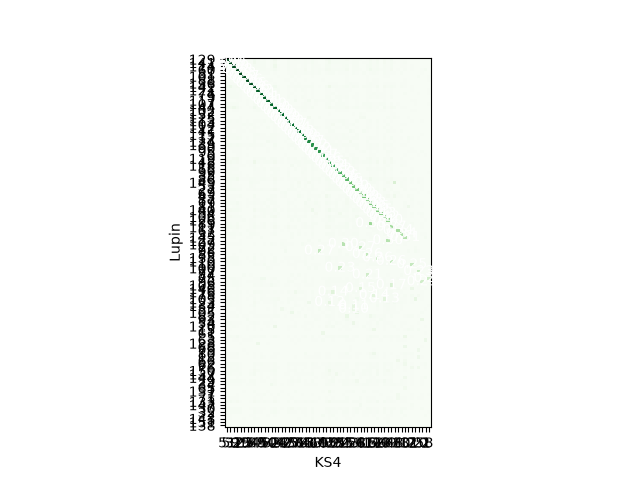

In [22]:
comp = si.compare_two_sorters(sorting_lupin, sorting_kilosort, 'Lupin', 'KS4')
w = si.plot_agreement_matrix(comp)
import pylab as plt
plt.show()

# Analyze Sorting

We now have a sorter and recording. Great! Now we can get on to the fun stuff: what shape are our unit templates? Which units are correlated with each other? Where on the probe are the units? This require computing extra information. In `SpikeInterface` we do this by creating an object called a `SortingAnalyzer`. 

A `SortingAnalyzer` combines a recording with a sorting in a unified way, no matter which sorter or recording format you used. Once you have an analyzer, you can compute postprocessing _extensions_ (like spike locations, waveforms, template metrics, ...) in exactly the same way for every sorter. They can also be used to keep track of curation, merging and splitting, and more.

This unified framework has several benefits. The main one is that the analyzer defines a sorter-agnostic format for post-sorting analysis. Hence:
- You can compare sorters on a level playing field (i.e. all the extensions are computed in the same way, for all sorters)
- Your postprocessing pipeline can be identical, whether using mountainsort to sort tetrode data or kilosort to sort NeuroPixel data, creating a unified pipeline in your lab.
- External tools have a simple starting point to work from. This should make tooling in the community easier, and there are already several examples of this:
  - NeuronConv contains a `SortingAnalyzerToNWB` function
  - spikeinterface-gui, sortingview and UnitMatch can take an analyzer as their initial input.
  - UnitRefine
  - BombCell
  - IBL viewer tools

Hopefully you're now convinced that creating a `SortingAnalyzer` will make your life easier, and smooth the path to using new tools in your analysis pipeline. So, let's make one.

When you make the analyzer, you can either make in _in memory_ or _in folder_. 

In [23]:
analyzer_in_memory = si.create_sorting_analyzer(
    sorting=sorting_lupin,
    recording=preprocessed_recording, 
)

analyzer_in_folder = si.create_sorting_analyzer(
    sorting=sorting_lupin, 
    recording=preprocessed_recording, 
    folder=results_folder / f"analyzer_lupin",
    format="binary_folder",
)

/run/media/pierre/Secondary/pierre/softwares/spikeinterface/src/spikeinterface/core/basesorting.py:655: UserWarning: The recording registered to this sorting object will not be saved to disk. Reloading the sorting later will not include the recording
  warnings.warn(


When in memory, the analyzer is stored in RAM. This makes computation faster, but will use more RAM. You can save your `analyzer_in_memory` to a folder at any point using `analyzer_in_memory.save_as` (more info in [Postprocessing docs](https://spikeinterface.readthedocs.io/en/stable/modules/postprocessing.html)). For this demo, we'll use a folder based analyzer. Go take a look in the folder. You'll see that it contains recording information, sorting information and more!

# Extensions

Each thing-you'd-like-to-compute is stored as an Extention of the analyzer. Let's compute the templates: the averaged waveforms from all (or a large random sample of) individual spikes.

In [24]:
analyzer_in_folder.compute("templates")

AssertionError: Extension templates requires random_spikes|waveforms to be computed first

Oh no - an error! This is due to the fact that extensions depend on each other. For example, you can't compute template similarity (how similar unit templates are to one another) without computing templates. The full dependency graph can be seen here:

![image](images/parent_child.svg)

So, when we compute extensions we need to know which _other_ extensions we need to compute beforehand... Let's compute a few. You can either compute one at a time, or give the `analyzer` a big dictionary of extensions (recommended! It will do some smart stuff to save some computation time):

In [25]:
# just one
analyzer_in_folder.compute("random_spikes", max_spikes_per_unit=1000)

# or lots: here we also specify some kwargs
analyzer_in_folder.compute({
    "templates": {},
    "waveforms": {},
    "correlograms": {},
    "noise_levels": {'method': 'std'},
    "spike_amplitudes": {},
    "spike_locations": {},
    "template_metrics": {'include_multi_channel_metrics': True},
    "unit_locations": {},
    "template_similarity": {'method': 'l1'},
    "quality_metrics": {},
})


compute_waveforms (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

noise_level (workers: 2 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

/run/media/pierre/Secondary/pierre/softwares/spikeinterface/src/spikeinterface/metrics/template/template_metrics.py:302: UserWarning: With less than 10 channels, multi-channel metrics might not be reliable.
  warnings.warn(


Compute : spike_amplitudes + spike_locations (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/…

/run/media/pierre/Secondary/pierre/softwares/spikeinterface/src/spikeinterface/core/analyzer_extension_core.py:1207: UserWarning: The following metrics will not be computed due to missing dependencies: ['d_prime', 'silhouette', 'mahalanobis', 'nearest_neighbor']
  warnings.warn(
/home/pierre/sorting/lib/python3.13/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/pierre/sorting/lib/python3.13/site-packages/numpy/_core/_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/home/pierre/sorting/lib/python3.13/site-packages/numpy/_core/_methods.py:211: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)
/run/media/pierre/Secondary/pierre/softwares/spikeinterface/src/spikeinterface/metrics/quality/misc_metrics.py:1006: UserWarning: Amplitude cutoff set to NaN for units [np.int64(

In [26]:
analyzer_in_folder

SortingAnalyzer: 60 channels - 108 units - 1 segments - binary_folder - sparse - has recording
Loaded 11 extensions: random_spikes, waveforms, templates, correlograms, noise_levels, template_metrics, unit_locations, template_similarity, spike_amplitudes, spike_locations, quality_metrics

To see which extensions are available to compute, use `analyzer_in_folder.get_computable_extensions()`. A good way to see which arguments an extension accepts, you can use e.g. `analyzer_in_folder.get_default_extension_params('template_metrics')`

Now take another look in your analyzer folder. You'll find lots of new folders containing your extensions! You can load this data directly, but `SpikeInterface` contains a lot of handy loader functions. The notation is always `analyzer.get_extension("extension_name").get_data()`. Let's look at the quality metrics. These are measures of how _good_ a unit is (more details: https://spikeinterface.readthedocs.io/en/latest/modules/qualitymetrics.html) Note that which quality metrics are computed depends on which other extensions you've computed.

In [27]:
quality_metrics = analyzer_in_folder.get_extension("quality_metrics").get_data()
quality_metrics

,num_spikes,firing_rate,presence_ratio,snr,isi_violations_ratio,isi_violations_count,rp_contamination,rp_violations,sliding_rp_violation,sync_spike_2,...,amplitude_cv_median,amplitude_cv_range,amplitude_cutoff,noise_cutoff,noise_ratio,amplitude_median,drift_ptp,drift_std,drift_mad,sd_ratio
0,366,4.066667,1.0,5.221157,0.895817,4,1.000000,2,NaN,0.057377,...,NaN,NaN,NaN,2.158081,0.172840,-109.980003,NaN,NaN,NaN,1.984500
2,469,5.211111,1.0,3.818527,0.136388,1,0.231341,1,NaN,0.087420,...,NaN,NaN,NaN,-0.154751,0.046667,-79.559998,NaN,NaN,NaN,1.129635
5,2071,23.011111,1.0,5.015656,0.062951,9,0.076358,7,0.085,0.060357,...,0.233564,0.136559,0.0,-0.041228,0.093492,-103.154999,NaN,NaN,NaN,1.237096
7,351,3.900000,1.0,3.572797,0.000000,0,0.000000,0,NaN,0.059829,...,NaN,NaN,NaN,-0.269594,0.118056,-67.860001,NaN,NaN,NaN,1.222409
9,1252,13.911111,1.0,5.554943,0.000000,0,0.000000,0,0.040,0.054313,...,0.201320,0.134227,0.0,-0.370113,0.071738,-112.709999,NaN,NaN,NaN,1.182868
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
146,122,1.355556,1.0,5.953948,2.015587,1,0.000000,0,NaN,0.090164,...,NaN,NaN,NaN,-0.377344,0.052632,-119.242493,NaN,NaN,NaN,1.297799
147,11,0.122222,1.0,6.450894,0.000000,0,0.000000,0,NaN,0.000000,...,NaN,NaN,NaN,-0.165690,0.045455,-130.649994,NaN,NaN,NaN,1.079083
149,537,5.966667,1.0,4.489010,2.392768,23,1.000000,16,NaN,0.068901,...,0.279846,0.308659,0.0,-0.011558,0.124654,-98.864998,NaN,NaN,NaN,1.198815
150,1016,11.288889,1.0,3.470088,0.116250,4,0.193000,4,0.190,0.067913,...,0.427530,0.286056,0.0,0.131669,0.073846,-121.290001,NaN,NaN,NaN,1.490041


This is a `pandas` dataframe with information about each unit. Nice.

We can get the "raw" extension data from any other extensions too

In [28]:
template_similarity_data = analyzer_in_folder.get_extension("template_similarity").get_data()
template_similarity_data

array([[1.        , 0.56866676, 0.26737988, ..., 0.        , 0.        ,
        0.        ],
       [0.56866676, 1.        , 0.38436425, ..., 0.        , 0.        ,
        0.        ],
       [0.26737988, 0.38436425, 1.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 1.        , 0.3902831 ,
        0.32478225],
       [0.        , 0.        , 0.        , ..., 0.3902831 , 1.        ,
        0.47147912],
       [0.        , 0.        , 0.        , ..., 0.32478225, 0.47147912,
        1.        ]], shape=(108, 108), dtype=float32)

`SpikeInterface` also supports lots of plotting functions that are related to extensions (see more: https://spikeinterface.readthedocs.io/en/latest/modules/widgets.html#available-plotting-functions). Let's plot the spike locations, then a summary plot.

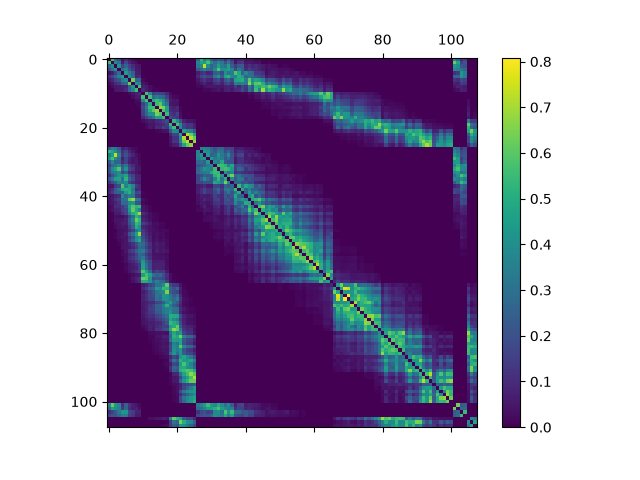

In [29]:
si.plot_template_similarity(analyzer_in_folder)

In [30]:
%matplotlib widget
si.plot_amplitudes(analyzer_in_folder, backend="ipywidgets")

AppLayout(children=(VBox(children=(UnitSelector(children=(Label(value='Units', layout=Layout(justify_content='…

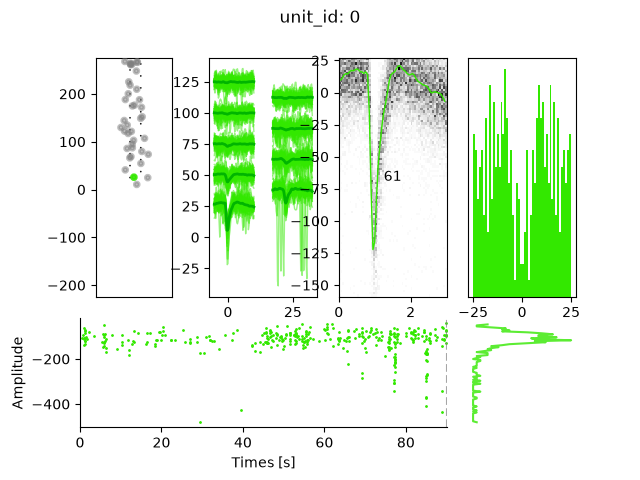

In [34]:
si.plot_unit_summary(analyzer_in_folder, unit_id=0)
plt.show()

In [35]:
si.plot_quality_metrics(analyzer_in_folder, backend="ipywidgets")

/run/media/pierre/Secondary/pierre/softwares/spikeinterface/src/spikeinterface/widgets/metrics.py:66: UserWarning: Skipping ['drift_ptp', 'drift_std', 'drift_mad'] because they contain all NaNs
  warnings.warn(f"Skipping {nan_metrics} because they contain all NaNs")


AppLayout(children=(UnitSelector(children=(Label(value='Units', layout=Layout(justify_content='center')), Sele…

# Export

We are trying to improve `export` options for the `SortingAnalyzer` so that SpikeInterface works with other tools. For example, we recently introduced the ability to `export_to_pynapple` (https://pynapple.org/)

In [36]:
spikes = si.to_pynapple_tsgroup(analyzer_in_folder)
spikes

Index    rate      x       y       z      num_spikes    firing_rate    presence_ratio    ...
-------  --------  ------  ------  -----  ------------  -------------  ----------------  -----
0        4.06674   8.16    25.81   1.0    366           4.07           1.0               ...
2        5.2112    -9.92   41.05   2.5    469           5.21           1.0               ...
5        23.01151  24.71   79.55   13.94  2071          23.01          1.0               ...
7        3.90007   30.36   107.01  1.0    351           3.9            1.0               ...
9        13.91135  22.25   148.71  1.0    1252          13.91          1.0               ...
10       9.4335    -12.17  144.28  1.0    849           9.43           1.0               ...
13       4.93342   19.82   187.76  17.66  444           4.93           1.0               ...
...      ...       ...     ...     ...    ...           ...            ...               ...
144      4.35563   -0.46   66.1    7.72   392           4.36        

If you want to know more about Pynapple, and use it to study the head direction cells in this dataset, there's a whole chapter about it on the [Open Software Summer School course](https://neuroinformatics.dev/course_ephys_osss/pynapple.html).

Another export option is `export_report`. This creates a cute little report about all your units:

In [ ]:
si.export_report(analyzer_in_folder, output_folder=results_folder / "lupin_report")